In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
from datetime import datetime

In [2]:
# filepaths
meb_file = r'data\MEBCro_for.nc'
fsm_file = r'data\FSM_all_corr.nc'
path_snow=r'data\snow_metrics.nc'
terrain_file = r'data\FSM_all.nc'

# reading both simulations
meb_all = xr.open_dataset(meb_file,decode_times=True)
fsm_all = xr.open_dataset(fsm_file,decode_times=True)
ds_snow = xr.open_dataset(path_snow,decode_times=True)
lus =xr.open_dataset(terrain_file,decode_times=True)

# aggregate to monthly vaulues for the radiation analysis
fsm_rad = fsm_all.groupby("time.month").mean("time")
meb_rad = meb_all.groupby("time.month").mean("time")

C:\Users\mazzottg\AppData\Local\Temp\ipykernel_14792\1713189257.py:44: RuntimeWarning: Mean of empty slice
  SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan


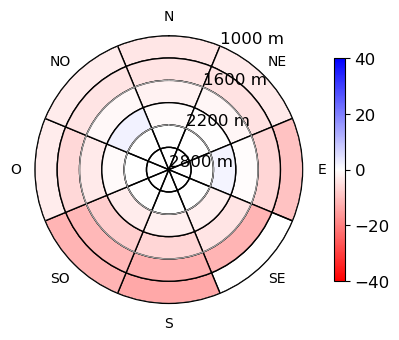

In [3]:
altitudes = lus['dem'].values.flatten() ## On récupére les données d'altitude
aspect = lus['aspect'].values.flatten()
forest = lus['forest'].values.flatten()
lai = lus['lai'].values.flatten()

## On définit les cadrants
angle = np.array([22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5])  ## ne pas modifier (Angles pour avoir 8 cadrants)
alt = np.arange(1000, 2801, 300)   ## à modifier si on veut aller de 500 à 3500m

primary_mask = (forest >= 0.1)
primary_mask = np.where(primary_mask,1,np.nan)

for s in range(len(ds_snow.season)) :
    curr_season = ds_snow.season[s]

    meb_peak = ds_snow["Peak_SWE"].sel(simulation='MEB_FOR', season = curr_season).values.flatten() 
    fsm_peak = ds_snow["Peak_SWE"].sel(simulation='FSM_FOR', season = curr_season).values.flatten() 
    meb_scd = ds_snow["Snow_duration"].sel(simulation='MEB_FOR', season = curr_season).values.flatten() 
    fsm_scd = ds_snow["Snow_duration"].sel(simulation='FSM_FOR', season = curr_season).values.flatten() 
    
    primary_mask = np.where(meb_peak > 0.1, primary_mask, np.nan)
    primary_mask = np.where(fsm_peak > 0.1, primary_mask, np.nan)
    primary_mask = np.where(meb_scd > 2, primary_mask, np.nan)
    primary_mask = np.where(fsm_scd > 2, primary_mask, np.nan)


# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = meb_rad["SW"].sel(month=3).values.flatten() - fsm_rad["swsc_for"].sel(month=3).values.flatten()
variable = np.where(primary_mask ==1 ,variable,np.nan)

for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5)) & (forest >=0.1) & (lai > 3.5))
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]) & (forest >=0.1)& (lai > 3.5))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-40,vmax=40)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200, 1600, 1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
mois = False
unite = 'mm'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-40,40)


In [8]:
np.nanmean(variable)

np.float64(3.560919527169441)

In [9]:
swr_dense= np.where(lai > 3.5,variable,np.nan)
np.nanmean(swr_dense)

np.float64(-4.761310454010812)

In [10]:
swr_sparse= np.where(lai < 2,variable,np.nan)
np.nanmean(swr_sparse)

np.float64(12.792889873944146)

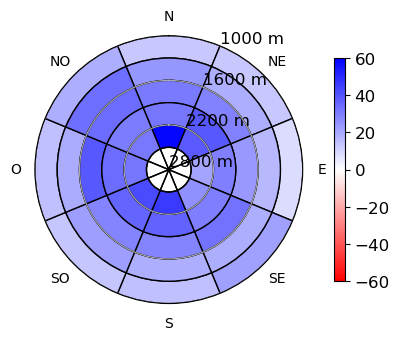

In [4]:
altitudes = lus['dem'].values.flatten() ## On récupére les données d'altitude
aspect = lus['aspect'].values.flatten()
forest = lus['forest'].values.flatten()

## On définit les cadrants
angle = np.array([22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5])  ## ne pas modifier (Angles pour avoir 8 cadrants)
alt = np.arange(1000, 2801, 300)   ## à modifier si on veut aller de 500 à 3500m

# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = meb_rad["LW"].sel(month=3).values.flatten()- fsm_rad["lwsc_for"].sel(month=3).values.flatten()
variable = np.where(primary_mask ==1 ,variable,np.nan)

for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5)) & (forest >=0.1) & (lai < 2) )
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]) & (forest >=0.1) & (lai < 2))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-60,vmax=60)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200, 1600, 1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
mois = False
unite = 'mm'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-60,60)


In [12]:
lwr_dense= np.where(lai > 3.5,variable,np.nan)
np.nanmean(lwr_dense)

np.float64(36.52933317563397)

In [13]:
lwr_sparse= np.where(lai < 2,variable,np.nan)
np.nanmean(lwr_sparse)

np.float64(27.972178400365056)

In [5]:
lw_meb = meb_rad["LW"].sel(month=3).values.flatten()/fsm_rad["lwsc_opn"].sel(month=3).values.flatten()
lw_fsm = fsm_rad["lwsc_for"].sel(month=3).values.flatten()/fsm_rad["lwsc_opn"].sel(month=3).values.flatten()

lw_meb = np.where(primary_mask ==1 ,lw_meb,np.nan)
lw_fsm = np.where(primary_mask ==1 ,lw_fsm,np.nan)

In [14]:
sw_meb = meb_rad["SW"].sel(month=3).values.flatten()/fsm_rad["swsc_opn"].sel(month=3).values.flatten()
sw_fsm = fsm_rad["swsc_for"].sel(month=3).values.flatten()/fsm_rad["swsc_opn"].sel(month=3).values.flatten()

sw_meb = np.where(primary_mask ==1 ,sw_meb,np.nan)
sw_fsm = np.where(primary_mask ==1 ,sw_fsm,np.nan)

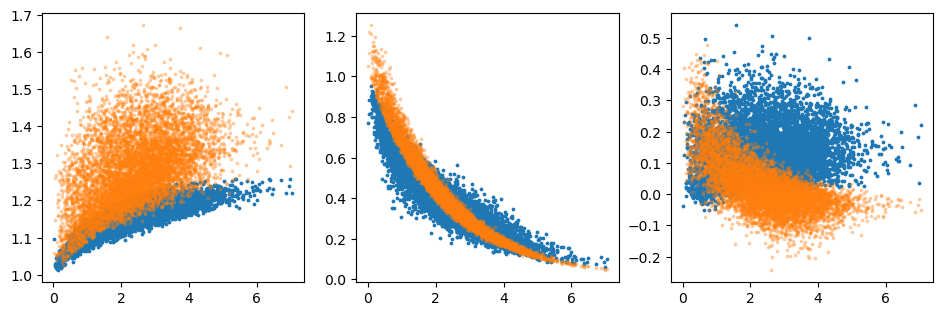

In [17]:
fig, axs = plt.subplots(1,3, figsize=(11.5, 3.5))

ax = axs[0]
ax.scatter(lai,lw_fsm,s=3,alpha=1)
ax.scatter(lai,lw_meb,s=3,alpha=0.3)

ax = axs[1]
ax.scatter(lai,sw_fsm,s=3,alpha=1)
ax.scatter(lai,sw_meb,s=3,alpha=0.3)

ax = axs[2]
ax.scatter(lai,lw_meb-lw_fsm,s=3,alpha=1)
ax.scatter(lai,sw_meb-sw_fsm,s=3,alpha=0.3)


In [ ]:
fig, axs = plt.subplots(1,3, figsize=(11.5, 3.5))

ax = axs[0]
ax.scatter(lai,lw_fsm,s=3,alpha=1)
ax.scatter(lai,lw_meb,s=3,alpha=0.3)
